
# Data Visualization with Matplotlib - Exercises 2

จงทำตามคำสั่งต่อไปนี้ด้วย data ที่กำหนดให้ต่อไปนี้


In [201]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## อ่านไฟล์ Superstore.csv

In [202]:
df = pd.read_csv('Superstore.csv',encoding = 'iso-8859-1')

In [203]:
df.head()

,Order ID,Customer Name,Segment,Day,Month,Year,Ship Mode,City,State,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,CA-2016-152156,Claire Gute,Consumer,8,11,2016,Second Class,Henderson,Kentucky,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,CA-2016-152156,Claire Gute,Consumer,8,11,2016,Second Class,Henderson,Kentucky,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,CA-2016-138688,Darrin Van Huff,Corporate,12,6,2016,Second Class,Los Angeles,California,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,US-2015-108966,Sean O'Donnell,Consumer,11,10,2015,Standard Class,Fort Lauderdale,Florida,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,US-2015-108966,Sean O'Donnell,Consumer,11,10,2015,Standard Class,Fort Lauderdale,Florida,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       9994 non-null   object 
 1   Customer Name  9994 non-null   object 
 2   Segment        9994 non-null   object 
 3   Day            9994 non-null   int64  
 4   Month          9994 non-null   int64  
 5   Year           9994 non-null   int64  
 6   Ship Mode      9994 non-null   object 
 7   City           9994 non-null   object 
 8   State          9994 non-null   object 
 9   Category       9994 non-null   object 
 10  Sub-Category   9994 non-null   object 
 11  Product Name   9994 non-null   object 
 12  Sales          9994 non-null   float64
 13  Quantity       9994 non-null   int64  
 14  Discount       9994 non-null   float64
 15  Profit         9994 non-null   float64
dtypes: float64(3), int64(4), object(9)
memory usage: 1.2+ MB


## Exercise 1

จงวาดกราฟแท่งแสดงรายได้ของปี 2014 - 2017 และตกแต่งให้สวยงาม


In [204]:
arr1 = df['Year'].unique()

In [205]:
arr2 = df.groupby('Year')['Sales'].sum()

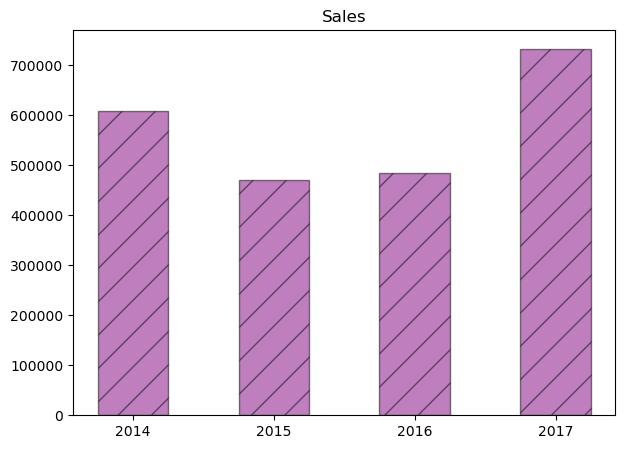

In [206]:
plt.figure(figsize = [7,5])
plt.bar(arr1,arr2,width = 0.5,color = 'purple', alpha = 0.5,hatch = '/',ec= 'k')
plt.xticks( [2014,2015,2016,2017] )
plt.title('Sales')
plt.show()

## Exercise 2

จงวาดกราฟวงกลม แสดงเปอร์เซ็นต์การขนส่งแต่ละแบบ ( Ship Mode ) พร้อมตกแต่งให้สวยงาม

In [207]:
t1 = df['Ship Mode'].unique()

In [208]:
df.groupby('Ship Mode')['Ship Mode'].count()

Ship Mode
First Class       1538
Same Day           543
Second Class      1945
Standard Class    5968
Name: Ship Mode, dtype: int64

In [209]:
arr3 = df['Ship Mode'].value_counts()

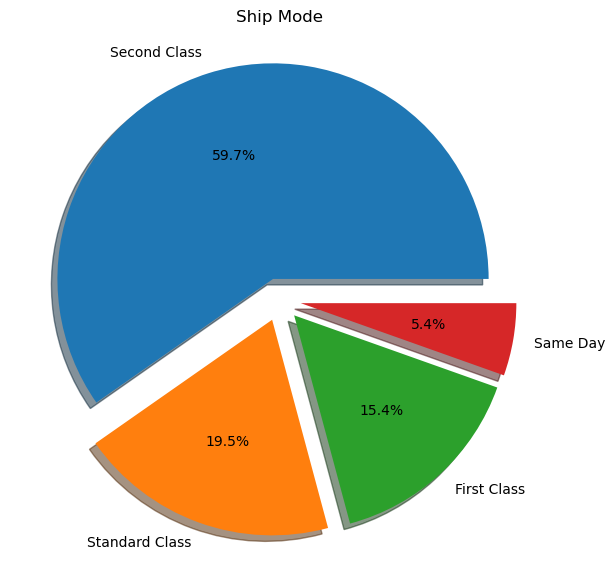

In [287]:
plt.figure(figsize = [7,7])
plt.pie(arr3,labels =  t1, autopct = '%.1f%%',explode = [0.1,0.1,0.1,0.1],shadow = True)
plt.title('Ship Mode')
plt.show()

## Exercise 3

จงวาดกราฟความถี่นับจำนวนส่วนลด (Discount) พร้อมตกแต่งให้สวยงาม

In [288]:
arr4 = df['Discount']

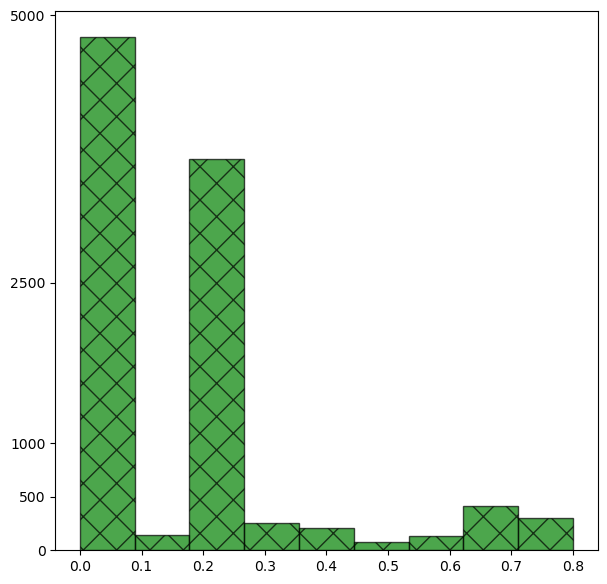

In [289]:
plt.figure(figsize = [7,7])
plt.hist(arr4, bins = 9,alpha = 0.7,color = 'green',ec = 'k',hatch = 'x')
plt.yticks([0,500,1000,2500,5000])
plt.show()

## Exercise 4

จงวาดกราฟจุด(Scatter) แสดงราคาขายกับกำไรที่ได้ (Sales , Profit) พร้อมตกแต่งให้สวยงาม

In [213]:
arr5 = df['Sales']
arr6 = df['Profit']

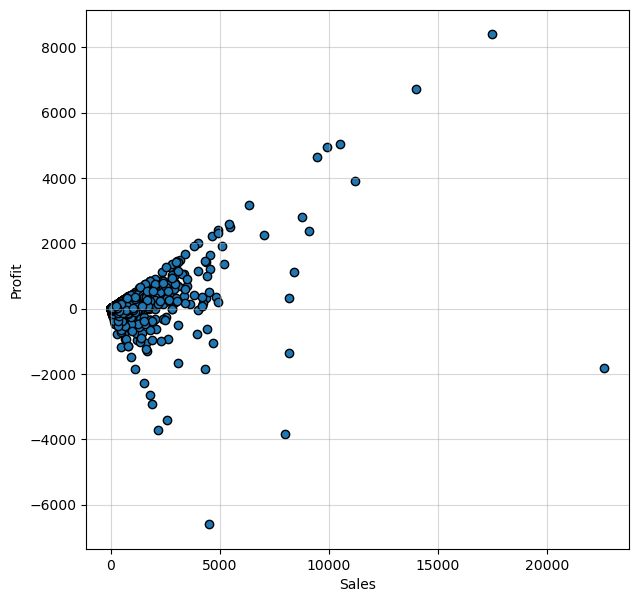

In [277]:
plt.figure(figsize = [7,7])
plt.scatter(arr5,arr6,ec = 'k')
plt.grid(alpha = 0.5)
plt.xlabel('Sales')
plt.ylabel('Profit')
plt.show()

## Exercise 5

จงวาดกราฟแท่งแสดงรายได้ของปี 2014 - 2017 ของแต่ละหมวดหมู่ในกราฟเดียว(แกน x เป็นปี) พร้อมตกแต่งให้สวยงาม

In [263]:
arr_df = {}
for i in range(0,df['Category'].nunique()) :
    arr_df[df['Category'].unique()[i]] = df[ df['Category'] == df['Category'].unique()[i] ].groupby('Year').sum()['Profit']

In [273]:
arr1 = np.array(sorted(df['Year'].unique()))
x1 = arr_df['Furniture']
x2 = arr_df['Office Supplies']
x3 = arr_df['Technology']

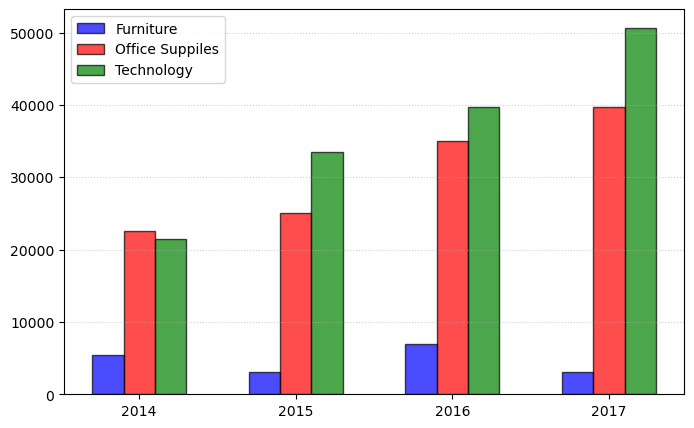

In [274]:
plt.figure(figsize = [8,5])
bw = 0.2
plt.bar(arr1,x1,width = 0.2,color = 'blue',alpha = 0.7,ec= 'k',label = 'Furniture')
plt.bar(arr1+bw,x2,width = 0.2,color = 'red',alpha = 0.7,ec= 'k',label = 'Office Suppiles')
plt.bar(arr1+2*bw,x3,width = 0.2,color = 'green',alpha = 0.7,ec= 'k',label = 'Technology')
plt.xticks( arr1+bw ,[2014,2015,2016,2017])
plt.grid(axis='y',ls=':',alpha = 0.6)
plt.legend()
plt.show()

## Exercise 6

จงวาดกราฟแท่งแสดงรายได้ของแต่ละหมวด ตั้งแต่ปี 2014-2017 แบบแยกกราฟ (1หมวด 1กราฟ) พร้อมตกแต่งให้สวยงาม

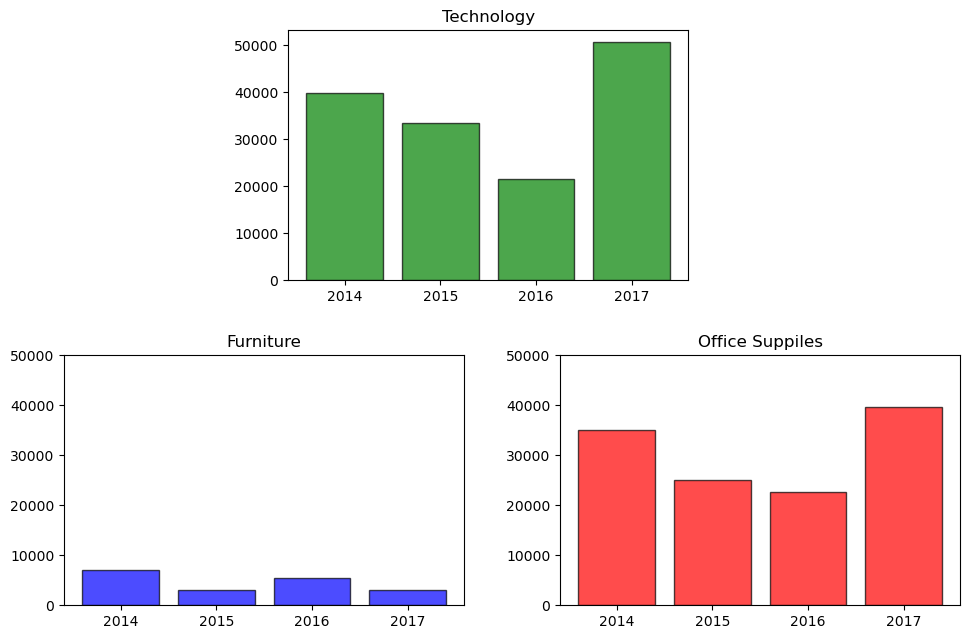

In [248]:
fig = plt.figure(figsize=[8,5])
a = fig.add_axes( [0.2,0,0.5,0.5] )
a.bar(arr1,x1,color = 'blue',alpha = 0.7,ec= 'k',lw = 1)
plt.xticks(np.arange(2014,2018,1))
plt.yticks([0,10000,20000,30000,40000,50000])
a.set_title('Furniture')

b = fig.add_axes( [0.82,0,0.5,0.5] )
b.bar(arr1,x2,color = 'red',alpha = 0.7,ec= 'k',lw = 1)
plt.xticks(np.arange(2014,2018,1))
plt.yticks([0,10000,20000,30000,40000,50000])
b.set_title('Office Suppiles')

c = fig.add_axes( [0.48,0.65,0.5,0.5] )
c.bar(arr1,x3,color = 'green',alpha = 0.7,ec= 'k',lw = 1)
plt.xticks(np.arange(2014,2018,1))
plt.yticks([0,10000,20000,30000,40000,50000])
c.set_title('Technology')

plt.show()

## Exercise 7

จงวาด Box plot ของยอดขาย และกำไร พร้อมตกแต่งให้สวยงาม (แนะนำให้แยกกราฟ)

In [249]:
Q1 = df['Sales'].quantile(0.25)
Q3 = df['Sales'].quantile(0.75)
IQR = Q3-Q1

upper = Q3 + IQR
lower = Q1 - IQR
new_df = df[ (df['Sales']>=lower)& (df['Sales']<=upper)]

C:\Users\aof_k\AppData\Local\Temp\ipykernel_77296\1435559692.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot( new_df['Sales'],labels = ['Sales'])


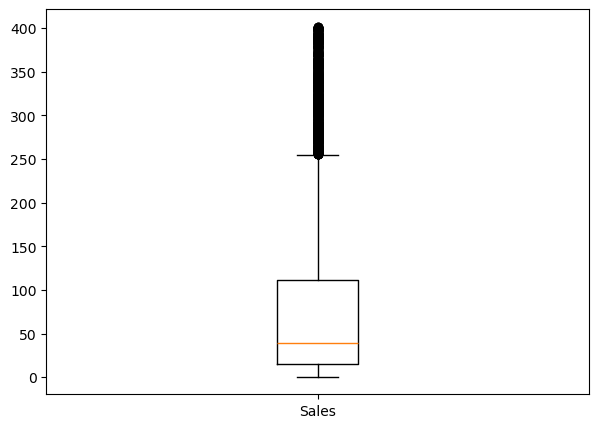

In [250]:
plt.figure(figsize = [7,5])
plt.boxplot( new_df['Sales'],labels = ['Sales'])
plt.show()

In [221]:
Q1 = df['Profit'].quantile(0.25)
Q3 = df['Profit'].quantile(0.75)
IQR = Q3-Q1

upper = Q3 + IQR
lower = Q1 - IQR
new_df = df[ (df['Profit']>=lower)& (df['Profit']<=upper)]

C:\Users\aof_k\AppData\Local\Temp\ipykernel_77296\386510465.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot( new_df['Profit'],labels = ['Profit'])


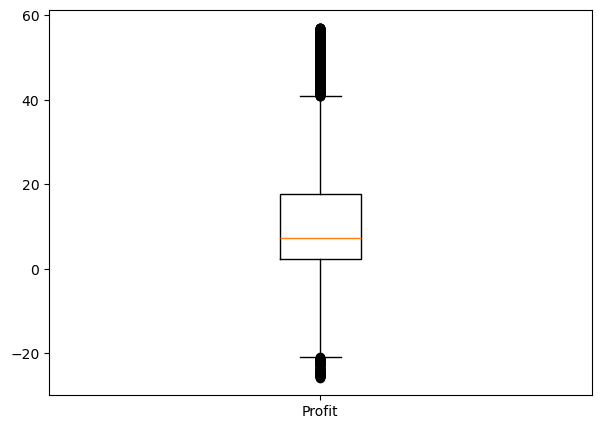

In [222]:
plt.figure(figsize = [7,5])
plt.boxplot( new_df['Profit'],labels = ['Profit'])
plt.show()

## Exercise 8

จงวาดกราฟแท่งแสดงจำนวน Furniture ที่ขายได้ในแต่ละไตรมาส (จำนวนให้นับจาก Quantity)

In [228]:
x = ['Q1','Q2','Q3','Q4']
y1 = df[(df['Category'] == 'Furniture') & 
        (df['Month'] >= 1) & (df['Month'] <= 3)]['Quantity'].sum()
y2 = df[(df['Category'] == 'Furniture') & 
        (df['Month'] >= 4) & (df['Month'] <= 6)]['Quantity'].sum()
y3 = df[(df['Category'] == 'Furniture') & 
        (df['Month'] >= 7) & (df['Month'] <= 9)]['Quantity'].sum()
y4 = df[(df['Category'] == 'Furniture') & 
        (df['Month'] >= 10) & (df['Month'] <= 12)]['Quantity'].sum()
y = [y1, y2, y3, y4]

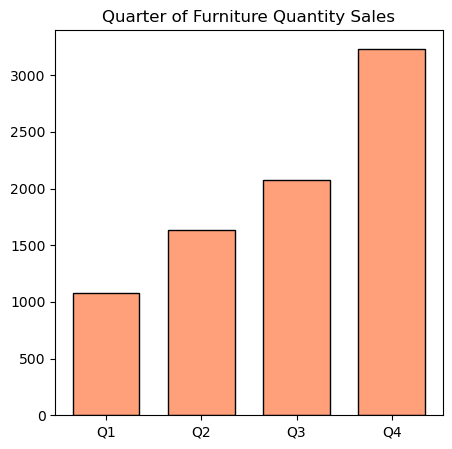

In [235]:
plt.figure(figsize = [5,5])
plt.bar(x,y,width = 0.7,color = 'lightsalmon',ec= 'k',label = 'Furniture')
plt.title('Quarter of Furniture Quantity Sales')
plt.show()